# Market Council: results notebook

> **This project is a prototype and is not financial advice.**

Veritas AI International High School Hackathon 2026, AI + Finance track.

This notebook shows the main results. **Every number comes from test years (2020–2026) that no model or setting
ever saw:** training used 1992–2019 only, and the training code physically can't open the test folder.

**The example user:** a S$500 budget, a maximum loss of S$50, holding each purchase for 20 trading days.

**The four strategies compared:**
- **Always buy:** S$500 at every decision.
- **Random:** buys at random as often as the council does.
- **Always buy + stop-loss:** S$500, sold if the loss reaches S$50, with realistic fills when prices gap overnight.
- **Council:** our system.

Each result is averaged over **20 fair decision calendars**, so no number depends on a lucky start date.
A decision is made every 5 trading days, and the S$500 growth uses one decision every 20 trading days. More detail is
in `RESULTS.md`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "eval" else Path.cwd()
summary = json.loads((ROOT / "results/summary.json").read_text())
ORDER = ["Always buy", "Random, same buy rate", "Always buy + stop-loss", "Council"]
FEATURED = {"DOW": "Main: the Dow + its companies", "AMD": "AMD (volatile)", "JNJ": "Johnson & Johnson (steady)",
            "MOS": "Mosaic (declining)", "DJI": "The Dow on its own"}
plt.rcParams.update({"text.parse_math": False, "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
COLORS = {"Always buy": "#9fb5ad", "Random, same buy rate": "#c9d5d0", "Always buy + stop-loss": "#b9822a", "Council": "#1e6e61"}
print("Councils with results:", ", ".join(summary))

Councils with results: DOW, AMD, JNJ, MOS, DJI, KO, CAT, MSFT, GS, HD, MRK, BA, IBM


## 1. The five featured councils

For each strategy:
- **S$500 became:** the average over the 20 calendars.
- **Range:** the worst and best calendar.
- **Worst drop:** the biggest fall from a high point.
- **Lost >S$50:** the number of purchases that broke the loss limit.

In [2]:
rows = []
for key, label in FEATURED.items():
    res = summary[key]["results"]
    for name in ORDER:
        x = res[name]
        rows.append({"Council": label, "Strategy": name,
                     "S$500 became": round(x["S500_becomes"]["mean"]),
                     "Profit %": f'{x["profit_pct"]["mean"]:+.0%}',
                     "Range": f'S${x["S500_becomes"]["min"]:,.0f} to S${x["S500_becomes"]["max"]:,.0f}',
                     "Worst drop": f'{x["worst_drop"]["mean"]:.0%}',
                     "Lost >S$50": round(x["lost_over_50"]["mean"], 1),
                     "Worst single loss": round(x["worst_loss"]["mean"])})
table = pd.DataFrame(rows).set_index(["Council", "Strategy"])
table

S$500 became Profit %  \
Council                       Strategy                                        
Main: the Dow + its companies Always buy                       890     +78%   
                              Random, same buy rate            890     +78%   
                              Always buy + stop-loss           915     +83%   
                              Council                          915     +83%   
AMD (volatile)                Always buy                      4793    +859%   
                              Random, same buy rate           4793    +859%   
                              Always buy + stop-loss          2994    +499%   
                              Council                         2708    +442%   
Johnson & Johnson (steady)    Always buy                      1108    +122%   
                              Random, same buy rate           1108    +122%   
                              Always buy + stop-loss           935     +87%   
                              Council                          949     +90%   
Mosaic (declining)            Always buy                       542      +8%   
                              Random, same buy rate            542      +8%   
                              Always buy + stop-loss           436     -13%   
                              Council                          435     -13%   
The Dow on its own            Always buy                       890     +78%   
                              Random, same buy rate            890     +78%   
                              Always buy + stop-loss           915     +83%   
                              Council                          915     +83%   

                                                                   Range  \
Council                       Strategy                                     
Main: the Dow + its companies Always buy                  S$804 to S$998   
                              Random, same buy rate       S$804 to S$998   
                              Always buy + stop-loss    S$790 to S$1,175   
                              Council                   S$792 to S$1,175   
AMD (volatile)                Always buy              S$3,430 to S$7,468   
                              Random, same buy rate   S$3,430 to S$7,468   
                              Always buy + stop-loss    S$869 to S$5,585   
                              Council                   S$551 to S$5,961   
Johnson & Johnson (steady)    Always buy                S$985 to S$1,360   
                              Random, same buy rate     S$985 to S$1,360   
                              Always buy + stop-loss    S$695 to S$1,214   
                              Council                   S$687 to S$1,254   
Mosaic (declining)            Always buy                  S$391 to S$793   
                              Random, same buy rate       S$391 to S$793   
                              Always buy + stop-loss      S$179 to S$844   
                              Council                     S$124 to S$989   
The Dow on its own            Always buy                  S$804 to S$998   
                              Random, same buy rate       S$804 to S$998   
                              Always buy + stop-loss    S$790 to S$1,175   
                              Council                   S$792 to S$1,175   

                                                     Worst drop  Lost >S$50  \
Council                       Strategy                                        
Main: the Dow + its companies Always buy                   -25%       673.0   
                              Random, same buy rate        -25%       673.0   
                              Always buy + stop-loss       -20%       338.6   
                              Council                      -20%       184.2   
AMD (volatile)                Always buy                   -62%        62.4   
                              Random, same buy rate        -62%        62.4   
          

## 2. Growth of S$500, with the range over 20 calendars

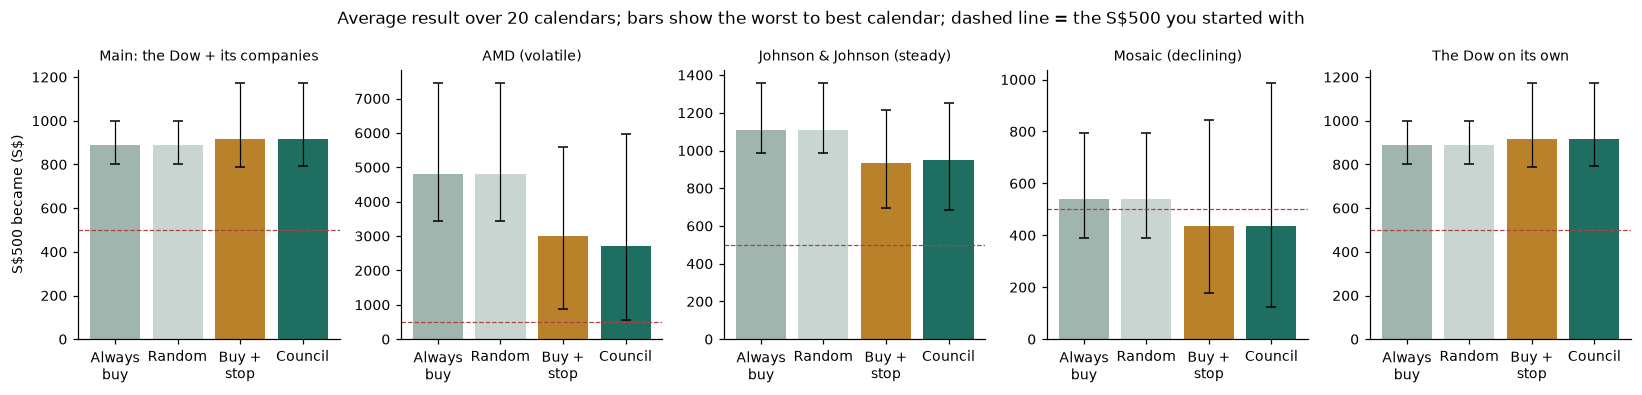

In [3]:
fig, axes = plt.subplots(1, len(FEATURED), figsize=(15, 3.6))
for ax, (key, label) in zip(axes, FEATURED.items()):
    res = summary[key]["results"]
    means = [res[n]["S500_becomes"]["mean"] for n in ORDER]
    lo = [res[n]["S500_becomes"]["mean"] - res[n]["S500_becomes"]["min"] for n in ORDER]
    hi = [res[n]["S500_becomes"]["max"] - res[n]["S500_becomes"]["mean"] for n in ORDER]
    ax.bar(range(4), means, color=[COLORS[n] for n in ORDER], yerr=[lo, hi], capsize=3, error_kw={"lw": 0.8})
    ax.axhline(500, color="#a9443d", lw=0.8, ls="--")
    ax.set_xticks(range(4), ["Always\nbuy", "Random", "Buy +\nstop", "Council"])
    ax.set_title(label, fontsize=9)
axes[0].set_ylabel("S$500 became (S$)")
fig.suptitle("Average result over 20 calendars; bars show the worst to best calendar; dashed line = the S$500 you started with")
fig.tight_layout()

## 3. Safety: purchases that broke the S$50 limit, across all 13 councils

This is the council's main strength. Lower is better.

The council had the fewest limit-breaking purchases in 12 of 13 councils.


,Always buy,Always buy + stop-loss,Council
Main (Dow + companies),673.0,338.6,184.2
AMD,62.4,26.0,5.2
Johnson & Johnson,1.8,5.2,2.2
Mosaic,60.8,20.6,8.6
Dow alone,5.4,2.2,2.0
Coca-Cola,6.6,2.0,0.6
Caterpillar,30.2,18.0,9.0
Microsoft,17.2,9.0,4.0
Goldman Sachs,16.2,9.8,4.8
Home Depot,24.8,7.4,2.8


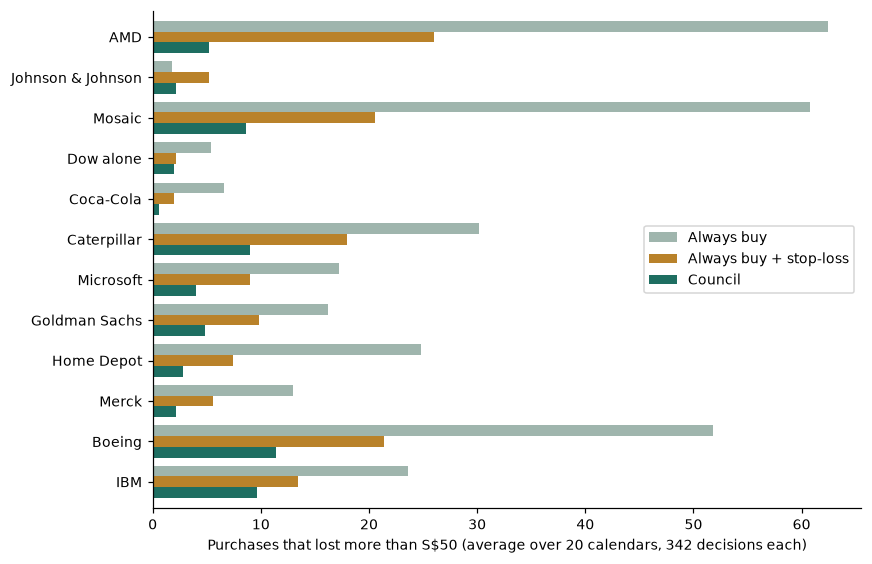

In [4]:
names = {"DOW": "Main (Dow + companies)", "DJI": "Dow alone", "JNJ": "Johnson & Johnson", "MOS": "Mosaic", "KO": "Coca-Cola",
         "CAT": "Caterpillar", "MSFT": "Microsoft", "GS": "Goldman Sachs", "HD": "Home Depot", "MRK": "Merck",
         "BA": "Boeing", "IBM": "IBM", "AMD": "AMD"}
safety = pd.DataFrame({names.get(k, k): {n: v["results"][n]["lost_over_50"]["mean"] for n in ["Always buy", "Always buy + stop-loss", "Council"]}
                       for k, v in summary.items()}).T
fewest = (safety.idxmin(axis=1) == "Council").sum()
print(f"The council had the fewest limit-breaking purchases in {fewest} of {len(safety)} councils.")
plot = safety.drop(index="Main (Dow + companies)")   # the main council has ~10,000 decisions, so it's shown in the table instead
ax = plot.plot.barh(figsize=(8, 5.2), color=[COLORS["Always buy"], COLORS["Always buy + stop-loss"], COLORS["Council"]], width=0.8)
ax.set_xlabel("Purchases that lost more than S$50 (average over 20 calendars, 342 decisions each)")
ax.invert_yaxis(); plt.tight_layout()
safety.round(1)

## 4. Can the models predict direction?

These are validation years (2016–2019), predicted by models trained only on 1992–2015. "Always up" scores as well
as almost every analyst, so **none of them learned to predict direction**. That's why the tuned system
switches its direction check off. Its useful AI is the **risk** side: sizing purchases and placing stops.

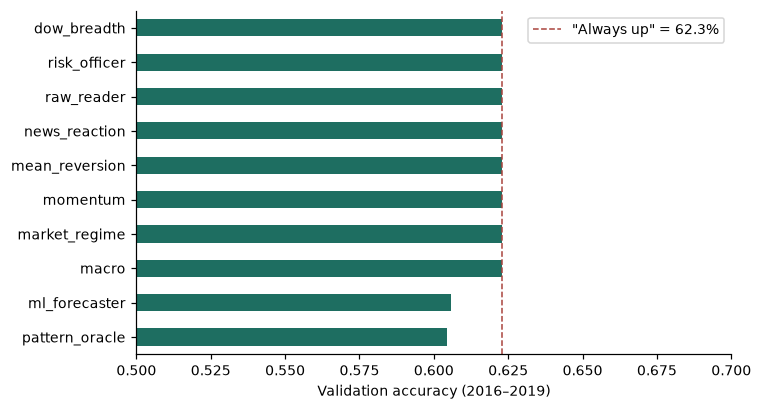

In [5]:
tr = json.loads((ROOT / "models/track_records.json").read_text())
val = json.loads((ROOT / "models/council_validation.json").read_text())
acc = pd.Series({k: v["validation_accuracy"] for k, v in tr.items() if k != "devils_advocate"}).sort_values()
ax = acc.plot.barh(figsize=(7, 3.8), color="#1e6e61")
ax.axvline(val["base_rate_up"], color="#a9443d", ls="--", lw=1, label=f'"Always up" = {val["base_rate_up"]:.1%}')
ax.set_xlim(0.5, 0.7); ax.set_xlabel("Validation accuracy (2016–2019)"); ax.legend(); plt.tight_layout()

## 5. Where it fails

**AMD rose about 10× in 2020–2026.** The council's stop-loss kept selling during dips that later recovered, so it
kept far less of the rise than simply holding. Its safety cost a lot of profit here.

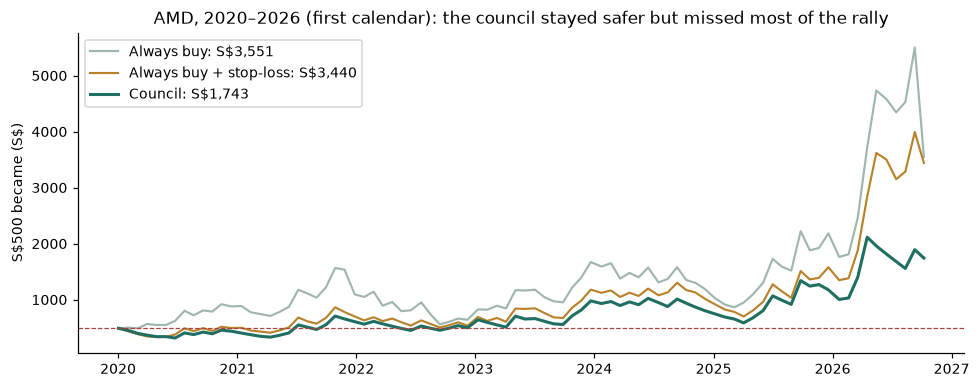

In [6]:
def curves(program):
    env = {**os.environ, "PYTHONPATH": str(ROOT), "VERITAS_SCENARIO": program}
    out = subprocess.run([sys.executable, "-m", "eval.curves"], cwd=ROOT, env=env, capture_output=True, text=True)
    return json.loads(out.stdout.strip().splitlines()[-1])

amd = curves("AMD")
dates = pd.to_datetime(amd["dates"])
fig, ax = plt.subplots(figsize=(9, 3.6))
for n in ["Always buy", "Always buy + stop-loss", "Council"]:
    ax.plot(dates, amd[n], label=f'{n}: S${amd[n][-1]:,.0f}', color=COLORS[n], lw=2 if n == "Council" else 1.4)
ax.axhline(500, color="#a9443d", lw=0.8, ls="--"); ax.set_ylabel("S$500 became (S$)")
ax.set_title("AMD, 2020–2026 (first calendar): the council stayed safer but missed most of the rally"); ax.legend(); plt.tight_layout()

**Calendar luck is large.** For Mosaic, the council's S$500 ended anywhere between about S$124 and S$989 depending only
on which days were decision days. One backtest on its own can be very misleading, which is why every number here
is an average over 20 calendars.

In [7]:
m = summary["MOS"]["results"]
pd.DataFrame({n: {"worst calendar": round(m[n]["S500_becomes"]["min"]), "average": round(m[n]["S500_becomes"]["mean"]),
                  "best calendar": round(m[n]["S500_becomes"]["max"])} for n in ORDER}).T

,worst calendar,average,best calendar
Always buy,391,542,793
"Random, same buy rate",391,542,793
Always buy + stop-loss,179,436,844
Council,124,435,989


## Honesty notes

- **Every setting was chosen on training years only:** walk-forward years for sizing, 2016–2019 for the direction
  check. The test years were never used to choose anything.
- **The test years were looked at during development,** and some design ideas came after seeing earlier results.
  The 8 extra companies, run with settings frozen beforehand, are the freshest check.
- **AMD, Johnson & Johnson and Mosaic were picked by looking at their full histories,** so treat them as stress
  tests.
- **Not modelled:** trading fees and slippage.

*This project is a prototype and is not financial advice.*